# Seleccion temporal de modelos
Tarea inicial: predecir el TSI provisional del siguiente dia dentro de cada fuente. Se comparan persistencia, Ridge y Random Forest con una particion temporal por fuente.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, wilcoxon
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
INPUT = PROJECT_ROOT / 'data' / '04_model_output' / 'features' / 'tsi_daily_features.parquet'
OUTPUT_DIR = PROJECT_ROOT / 'data' / '04_model_output' / 'modeling'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
features = pd.read_parquet(INPUT).sort_values(['fuente', 'fecha']).reset_index(drop=True)
features.shape

(9742, 19)

In [2]:
predictors = ['tsi_provisional_media', 'tsi_lag_1', 'tsi_lag_7', 'delta_1', 'media_movil_3', 'media_movil_7', 'desviacion_movil_7', 'dia_semana', 'mes', 'es_fin_de_semana', 'observaciones']
target = 'objetivo_tsi_siguiente'
model_data = features.dropna(subset=predictors + [target]).copy()
model_data['fuente_original'] = model_data['fuente']
parts = []
for source, group in model_data.groupby('fuente', sort=False):
    group = group.sort_values('fecha').copy()
    n = len(group)
    train_end = int(n * 0.60)
    validation_end = int(n * 0.80)
    group['split'] = ['train'] * train_end + ['validation'] * (validation_end - train_end) + ['test'] * (n - validation_end)
    parts.append(group)
model_data = pd.concat(parts, ignore_index=True)
model_data = pd.get_dummies(model_data, columns=['fuente'], dtype=float)
source_columns = [column for column in model_data.columns if column.startswith('fuente_') and column != 'fuente_original']
feature_columns = predictors + source_columns
train = model_data[model_data['split'] == 'train']
validation = model_data[model_data['split'] == 'validation']
test = model_data[model_data['split'] == 'test']
print('train=', len(train), 'validation=', len(validation), 'test=', len(test))
display(model_data.groupby('split').size())

train= 5827 validation= 1944 test= 1946


split
test          1946
train         5827
validation    1944
dtype: int64

In [3]:
X_train, y_train = train[feature_columns], train[target]
X_validation, y_validation = validation[feature_columns], validation[target]
X_test, y_test = test[feature_columns], test[target]
models = {
    'ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'random_forest': RandomForestRegressor(n_estimators=150, min_samples_leaf=5, random_state=42, n_jobs=-1),
}
validation_predictions = {'baseline_persistencia': validation['tsi_lag_1'].to_numpy()}
for name, model in models.items():
    model.fit(X_train, y_train)
    validation_predictions[name] = model.predict(X_validation)
validation_metrics = []
for name, prediction in validation_predictions.items():
    validation_metrics.append({'modelo': name, 'mae': mean_absolute_error(y_validation, prediction), 'rmse': mean_squared_error(y_validation, prediction) ** 0.5, 'r2': r2_score(y_validation, prediction)})
validation_df = pd.DataFrame(validation_metrics).sort_values('mae')
print('Seleccion en validacion temporal:')
display(validation_df)
selected_model_name = validation_df.iloc[0]['modelo']
print('modelo_seleccionado=' + selected_model_name)

train_validation = pd.concat([train, validation], ignore_index=True)
X_train_validation, y_train_validation = train_validation[feature_columns], train_validation[target]
predictions = {'baseline_persistencia': test['tsi_lag_1'].to_numpy()}
for name, model in models.items():
    model.fit(X_train_validation, y_train_validation)
    predictions[name] = model.predict(X_test)
metrics = []
for name, prediction in predictions.items():
    metrics.append({'modelo': name, 'mae': mean_absolute_error(y_test, prediction), 'rmse': mean_squared_error(y_test, prediction) ** 0.5, 'r2': r2_score(y_test, prediction)})
metrics_df = pd.DataFrame(metrics).sort_values('mae')
print('Evaluacion final en prueba temporal:')
display(metrics_df)

Seleccion en validacion temporal:


,modelo,mae,rmse,r2
2,random_forest,2.626187,5.512361,0.935116
1,ridge,3.707048,6.927258,0.897532
0,baseline_persistencia,5.668108,11.492627,0.717965


modelo_seleccionado=random_forest
Evaluacion final en prueba temporal:


,modelo,mae,rmse,r2
2,random_forest,2.511087,5.274513,0.947871
1,ridge,3.514525,6.338738,0.924712
0,baseline_persistencia,5.302138,9.950087,0.814488


In [4]:
comparison = pd.DataFrame({'baseline': np.abs(y_test.to_numpy() - predictions['baseline_persistencia']), 'ridge': np.abs(y_test.to_numpy() - predictions['ridge']), 'random_forest': np.abs(y_test.to_numpy() - predictions['random_forest'])})
stat_rows = []
for model_name in ['ridge', 'random_forest']:
    paired_t = ttest_rel(comparison['baseline'], comparison[model_name])
    try:
        paired_w = wilcoxon(comparison['baseline'], comparison[model_name])
        wilcoxon_p = paired_w.pvalue
    except ValueError:
        wilcoxon_p = np.nan
    stat_rows.append({'modelo': model_name, 'mejora_mae_vs_baseline': comparison['baseline'].mean() - comparison[model_name].mean(), 't_pareada_p_valor': paired_t.pvalue, 'wilcoxon_p_valor': wilcoxon_p})
stats_df = pd.DataFrame(stat_rows)
display(stats_df)

,modelo,mejora_mae_vs_baseline,t_pareada_p_valor,wilcoxon_p_valor
0,ridge,1.787612,9.673231e-31,1.372203e-21
1,random_forest,2.791051,2.731364e-64,1.632495e-113


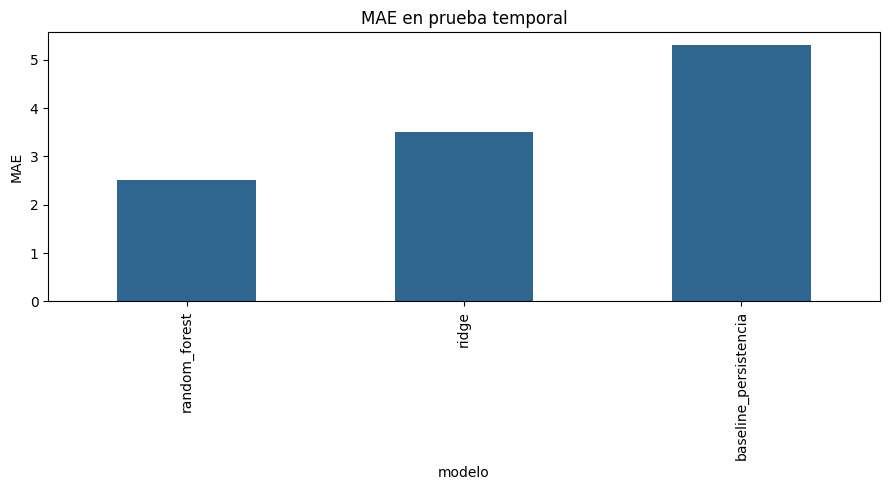

c:\Users\REYES\OneDrive\Desktop\terminado\portafolio data science\TSI\data\04_model_output\modeling


In [5]:
metrics_df.to_csv(OUTPUT_DIR / 'metricas_modelos.csv', index=False)
stats_df.to_csv(OUTPUT_DIR / 'pruebas_modelos_vs_baseline.csv', index=False)
predictions_frame = test[['fuente_original', 'fecha', target]].copy()
predictions_frame = predictions_frame.rename(columns={target: 'real'})
for name, prediction in predictions.items():
    predictions_frame[name] = prediction
predictions_frame.to_csv(OUTPUT_DIR / 'predicciones_prueba.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
metrics_df.plot.bar(x='modelo', y='mae', ax=ax, legend=False, color='#2f6690')
ax.set_title('MAE en prueba temporal')
ax.set_ylabel('MAE')
plt.tight_layout()
plt.show()
print(OUTPUT_DIR)

## Criterio de lectura
El modelo candidato debe mejorar el baseline en el conjunto de prueba, pero el valor p no basta para seleccionarlo: también se revisan MAE/RMSE, estabilidad por fuente y ausencia de fuga. Esta tarea predice un indicador provisional y no constituye todavía una etiqueta operativa de pre-colapso.